# Homework 2

**Contents**
1. Attention from first principles
2. From image to Transformer tokens
3. Pre-trained Transformers with HuggingFace pipelines

# 1. Attention from First Principles

Scaled dot-product attention is calculated as

$$
\text{Attention}(Q,K,V)=
\text{softmax}\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V
$$

Given

$$
Q=\begin{bmatrix}1&2\end{bmatrix},\quad
K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix},\quad
V=\begin{bmatrix}10&0\\0&20\\5&5\end{bmatrix}
$$

There is one query in $Q$, while $K$ and $V$ contain three tokens. Each key has 2 dimensions, so $d_k=2$.

I will refer to the three rows of $(K$) and $(V$) as token 1, token 2, and token 3.

### Step 1 — Raw attention scores $QK^\top$
First, I calculate the dot product between the query and each key:

* $(s_1=[1,2]\cdot[1,0]=1\cdot1+2\cdot0=1$)
* $(s_2=[1,2]\cdot[0,1]=1\cdot0+2\cdot1=2$)
* $(s_3=[1,2]\cdot[1,1]=1\cdot1+2\cdot1=3$)

Therefore,

$$
QK^\top=
\begin{bmatrix}1&2&3\end{bmatrix}
$$

At this point, token 3 has the highest raw attention score.

### Step 2 — Scaling by $\sqrt{d_k}$

Since $(d_k=2$),

$$
\sqrt{d_k}=\sqrt{2}\approx1.4142
$$

Dividing the scores by this value gives

$$
\frac{QK^\top}{\sqrt{2}}
=
\begin{bmatrix}
0.7071&1.4142&2.1213
\end{bmatrix}
$$

The scaling factor is used to keep the attention scores from becoming too large, which helps prevent the softmax from becoming too extreme.

### Step 3 — Softmax

Next, I apply the softmax function to the scaled scores.

First, the exponentials are

$$
e^{0.7071}=2.0281,\quad
e^{1.4142}=4.1133,\quad
e^{2.1213}=8.3421
$$

Their sum is

$$
\Sigma=2.0281+4.1133+8.3421=14.4835
$$

Therefore, the attention weights are

$$
\alpha=
\begin{bmatrix}
\frac{2.0281}{14.4835}&
\frac{4.1133}{14.4835}&
\frac{8.3421}{14.4835}
\end{bmatrix}
$$

$$
\alpha\approx
\begin{bmatrix}
0.1400&0.2840&0.5760
\end{bmatrix}
$$

The weights are positive and sum to approximately 1, so they show how much attention is given to each token.

### Step 4 — Final attention output

Finally, I multiply the attention weights by $(V$):

$$
\text{Output}=
0.1400[10,0]+
0.2840[0,20]+
0.5760[5,5]
$$

Calculating each part:

$$
=[1.400,0]+[0,5.680]+[2.880,2.880]
$$

Therefore,

$$
\text{Output}\approx[4.280,8.560]
$$

I also verify these calculations numerically with Python in the next cell.


In [1]:
import numpy as np

np.set_printoptions(precision=4, suppress=True)

Q = np.array([[1, 2]], dtype=float)                 # (1, 2)
K = np.array([[1, 0], [0, 1], [1, 1]], dtype=float) # (3, 2)
V = np.array([[10, 0], [0, 20], [5, 5]], dtype=float)  # (3, 2)

d_k = K.shape[1]

# 1) raw scores
scores = Q @ K.T
print("1) Raw scores QK^T          :", scores, "shape", scores.shape)

# 2) scaling
scaled = scores / np.sqrt(d_k)
print(f"2) Scaled scores (/sqrt({d_k}))   :", scaled)

# 3) softmax (numerically stable)
def softmax(x, axis=-1):
    x = x - x.max(axis=axis, keepdims=True)
    e = np.exp(x)
    return e / e.sum(axis=axis, keepdims=True)

weights = softmax(scaled)
print("3) Attention weights        :", weights, "| sum =", weights.sum())

# 4) output
output = weights @ V
print("4) Output  weights @ V      :", output, "shape", output.shape)

# 5) which token gets most attention
winner = int(weights.argmax()) + 1
print(f"5) Token with most attention: token {winner} (weight = {weights.max():.4f})")

1) Raw scores QK^T          : [[1. 2. 3.]] shape (1, 3)
2) Scaled scores (/sqrt(2))   : [[0.7071 1.4142 2.1213]]
3) Attention weights        : [[0.14  0.284 0.576]] | sum = 0.9999999999999999
4) Output  weights @ V      : [[4.2802 8.5598]] shape (1, 2)
5) Token with most attention: token 3 (weight = 0.5760)


### Results and interpretation

| Quantity          | Value                                   |
| ----------------- | --------------------------------------- |
| Scores $QK^\top$  | [1, 2, 3]                               |
| Scaled scores     | [0.7071, 1.4142, 2.1213]                |
| Attention weights | [0.1400, 0.2840, 0.5760]                |
| Attention output  | [4.2802, 8.5598] $\approx$ [4.28, 8.56] |

**Which token receives the most attention?**

Token 3 receives the most attention, with a weight of about **0.576 (57.6%)**. This is because it has the highest query-key score, so after applying softmax it gets the largest attention weight.

**Why?**

The query is $q=[1,2]$. Since the second component is larger, it contributes more to the dot product. For the three keys:

* Key 1: $[1,0]$ gives a score of $1$.
* Key 2: $[0,1]$ gives a score of $2$.
* Key 3: $[1,1]$ gives a score of $3$ because it matches both components of the query.

Therefore, the attention is highest for Token 3, followed by Token 2 and Token 1.

**Additional observations**

* Scaling the scores by $\sqrt{d_k}$ does not change their order, but it makes the attention distribution a little softer. In this example, the effect is not very large because $d_k=2$.
* The final output is a weighted average of the value vectors. Since Token 3 has the largest weight, its value vector $[5,5]$ has a strong influence on the final result. Token 2 also increases the second coordinate because its value is $[0,20]$ and it has the second-largest weight.
* The attention weights are determined by $Q$ and $K$, while $V$ contains the information that is actually combined to produce the final output.


---
# 2. From Image to Transformer Tokens

A Vision Transformer (ViT) processes an image as a sequence of small patches. Each patch is flattened and converted into an embedding of dimension $D$. Positional embeddings are then added so that the model can keep information about the position of each patch.


### Step 1 — Load and resize the image to 224 × 224

Original size (W,H): (451, 300) | mode: RGB
Resized image array shape (H, W, C): (224, 224, 3)
Value range: 0.0 - 0.827451


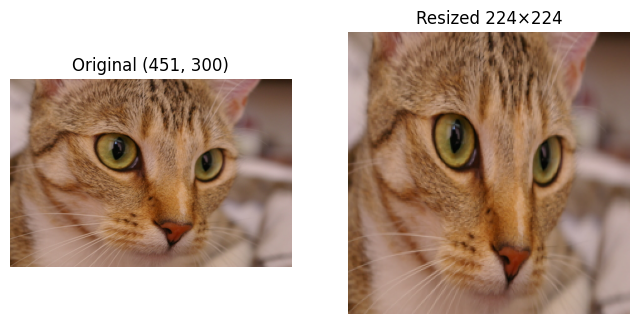

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data

# "Chelsea the cat" is a sample image bundled with scikit-image (no download needed).
img_orig = Image.fromarray(data.chelsea())
print("Original size (W,H):", img_orig.size, "| mode:", img_orig.mode)

IMG_SIZE = 224
img = img_orig.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
img_np = np.asarray(img).astype(np.float32) / 255.0      # scale to [0,1]

print("Resized image array shape (H, W, C):", img_np.shape)
print("Value range:", img_np.min(), "-", img_np.max())

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img_orig); ax[0].set_title(f"Original {img_orig.size}")
ax[1].imshow(img_np);   ax[1].set_title("Resized 224×224")
for a in ax: a.axis("off")
plt.show()

**Explanation.** The image is resized to $224\times224$ so that we can use the same fixed image size throughout the patchification process.

After converting the image to a NumPy array, its shape is $(H,W,C)=(224,224,3)$. Here, 224 is the image height, 224 is the width, and 3 represents the RGB color channels.


### Step 2 — Choose patch size, number of patches

In [3]:
PATCH = 16
assert IMG_SIZE % PATCH == 0, "image size must be divisible by the patch size"

patches_per_side = IMG_SIZE // PATCH
num_patches = patches_per_side ** 2
print(f"Patch size              : {PATCH}x{PATCH}")
print(f"Patches per side        : {IMG_SIZE}/{PATCH} = {patches_per_side}")
print(f"Total number of patches : {patches_per_side}x{patches_per_side} = {num_patches}")

Patch size              : 16x16
Patches per side        : 224/16 = 14
Total number of patches : 14x14 = 196


I chose a patch size of $16\times16$ pixels. This is convenient because $224$ is exactly divisible by $16$, so the image can be divided into patches without cropping or padding.

There are

$$
\frac{224}{16}=14
$$

patches along each side. Therefore, the total number of patches is

$$
14\times14=196.
$$

So, after patchification, the $224\times224$ image will be represented by **196 patches**, and each patch will have a spatial size of **$16\times16$ pixels**.

I chose $16\times16$ because it gives a reasonable balance between the amount of image detail and the number of patches. Smaller patches would produce many more tokens, while larger patches would contain less detailed information.


### Step 3 — Visualize the image with the patch grid

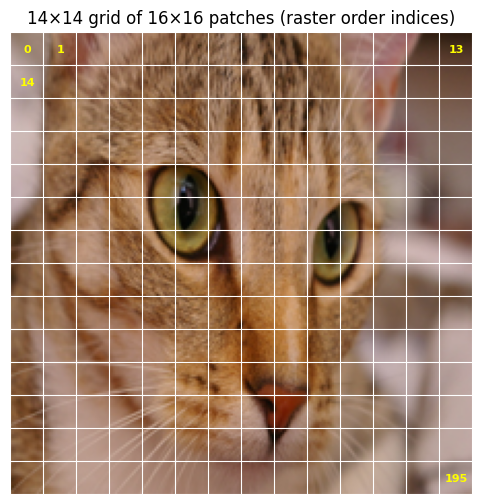

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_np)
for i in range(patches_per_side + 1):
    ax.axhline(i * PATCH - 0.5, color="white", lw=0.8)
    ax.axvline(i * PATCH - 0.5, color="white", lw=0.8)
# number a few patches in raster order (row-major) to show the ordering
for idx in [0, 1, 13, 14, 195]:
    r, c = divmod(idx, patches_per_side)
    ax.text(c * PATCH + PATCH / 2, r * PATCH + PATCH / 2, str(idx),
            color="yellow", ha="center", va="center", fontsize=8, weight="bold")
ax.set_title(f"{patches_per_side}×{patches_per_side} grid of {PATCH}×{PATCH} patches (raster order indices)")
ax.axis("off"); plt.show()

The image is divided into a $14\times14$ grid, where each cell represents one $16\times16$ patch. I also labeled a few patch indices to show the order in which the patches are arranged. The patches are read row by row, starting from the top-left corner.

### Step 4 — Extract the patches

In [5]:
H, W, C = img_np.shape

# (224,224,3) -> (14,16,14,16,3): split H into (rows, P) and W into (cols, P)
x = img_np.reshape(patches_per_side, PATCH, patches_per_side, PATCH, C)
print("After splitting H and W        :", x.shape, "(row, py, col, px, C)")

# -> (14,14,16,16,3): bring the two grid axes (row, col) to the front
x = x.transpose(0, 2, 1, 3, 4)
print("After transposing grid axes     :", x.shape, "(row, col, py, px, C)")

# -> (196,16,16,3): merge row & col into one token axis (row-major order)
patches = x.reshape(num_patches, PATCH, PATCH, C)
print("Patches tensor                  :", patches.shape, "(N, P, P, C)")

# sanity check: patch k must equal the direct slice of the image
k = 37; r, c = divmod(k, patches_per_side)
direct = img_np[r*PATCH:(r+1)*PATCH, c*PATCH:(c+1)*PATCH, :]
print(f"Patch {k} (row {r}, col {c}) equals direct slice:", np.array_equal(patches[k], direct))

After splitting H and W        : (14, 16, 14, 16, 3) (row, py, col, px, C)
After transposing grid axes     : (14, 14, 16, 16, 3) (row, col, py, px, C)
Patches tensor                  : (196, 16, 16, 3) (N, P, P, C)
Patch 37 (row 2, col 9) equals direct slice: True


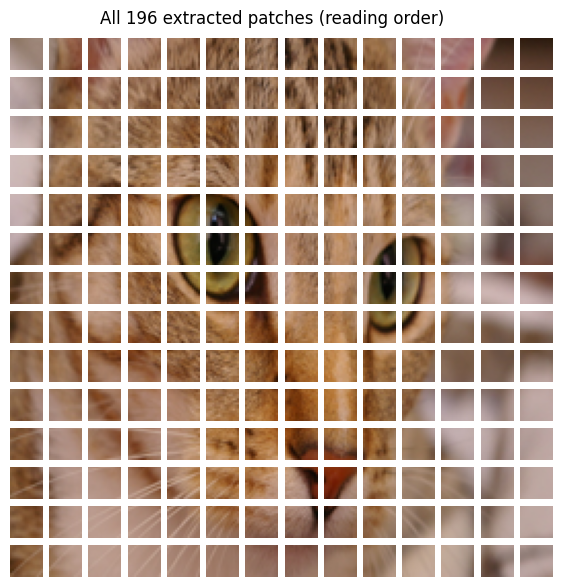

In [6]:
# Show all 196 patches as separated tiles
fig, axes = plt.subplots(patches_per_side, patches_per_side, figsize=(7, 7))
for i, a in enumerate(axes.ravel()):
    a.imshow(patches[i]); a.axis("off")
plt.suptitle("All 196 extracted patches (reading order)", y=0.92)
plt.show()

The resized image has shape $(224,224,3)$. Since $224=14\times16$, I first reshape the image so that the height and width are separated into the number of patches and the patch size.

The shape changes as follows:

$$
(224,224,3)
\rightarrow
(14,16,14,16,3)
\rightarrow
(14,14,16,16,3)
\rightarrow
(196,16,16,3).
$$

The final shape means that there are **196 patches**, and each patch has dimensions $16\times16\times3$. The last dimension is 3 because the image uses RGB color channels.

The patches are stored in row-major order, so the first patch is the top-left patch, followed by the patches to its right, and then the next row. I also used a sanity check to compare one extracted patch with the corresponding slice of the original image, and the result is `True`.


### Step 5 — Shape of one patch and why

Shape of one patch: (16, 16, 3) -> (patch_height, patch_width, channels)
Number of values in one patch: 768 = 16 * 16 * 3


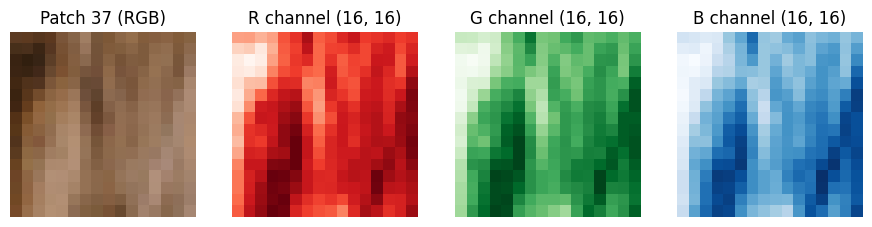

In [7]:
one = patches[37]
print("Shape of one patch:", one.shape, "-> (patch_height, patch_width, channels)")
print("Number of values in one patch:", one.size, "=", PATCH, "*", PATCH, "*", C)

fig, ax = plt.subplots(1, 4, figsize=(11, 3))
ax[0].imshow(one, interpolation="nearest"); ax[0].set_title("Patch 37 (RGB)")
for ch, name, cmap in zip(range(3), "RGB", ["Reds", "Greens", "Blues"]):
    ax[ch + 1].imshow(one[:, :, ch], cmap=cmap, interpolation="nearest"); ax[ch + 1].set_title(f"{name} channel {one[:,:,ch].shape}")
for a in ax: a.axis("off")
plt.show()

I selected patch 37 to inspect its shape. Its shape is $(16,16,3)$.

The first two dimensions come from the patch size:

* height = $16$ pixels
* width = $16$ pixels
* 3 color channels = R, G, and B

Therefore,

$$
16\times16\times3=768
$$

so one patch contains **768 pixel values**. The visualization also shows the original RGB patch and its three separate color channels.


### Step 6 — Flatten one patch

In [8]:
flat_one = one.reshape(-1)
print("Flattened patch shape:", flat_one.shape)
print("P_h * P_w * C =", PATCH, "*", PATCH, "*", 3, "=", PATCH * PATCH * 3)

# flatten all patches at once
patches_flat = patches.reshape(num_patches, -1)
print("All flattened patches:", patches_flat.shape, "-> (N, P*P*C)")

Flattened patch shape: (768,)
P_h * P_w * C = 16 * 16 * 3 = 768
All flattened patches: (196, 768) -> (N, P*P*C)


Before applying the linear projection, each $16\times16\times3$ patch needs to be converted into a one-dimensional vector.

The number of values in one patch is

$$
P_h\times P_w\times C
=16\times16\times3
=768.
$$

Therefore, after flattening, one patch changes from

$$
(16,16,3)\rightarrow(768,).
$$

Flattening only changes the shape of the data; it does not change the pixel values.

When all 196 patches are flattened, the shape becomes

$$
(196,768),
$$

where 196 is the number of patches and 768 is the number of values in each flattened patch.


### Step 7 — Linear projection → patch embeddings

In [9]:
D = 768                      # embedding dimension
rng = np.random.default_rng(42)

# Learnable linear projection E: R^{768} -> R^{D}. Randomly initialised here (it is learned in a real ViT).
W_proj = rng.normal(0.0, 0.02, size=(PATCH * PATCH * C, D)).astype(np.float32)
b_proj = np.zeros(D, dtype=np.float32)

patch_embeddings = patches_flat @ W_proj + b_proj
print("Projection matrix W shape :", W_proj.shape, "(P*P*C, D)")
print("Patch embeddings shape    :", patch_embeddings.shape, "(N, D)")
print("Parameters in projection  :", W_proj.size + b_proj.size)

Projection matrix W shape : (768, 768) (P*P*C, D)
Patch embeddings shape    : (196, 768) (N, D)
Parameters in projection  : 590592


Each flattened patch has 768 values, so I use a linear projection to convert it into an embedding of dimension $D=768$.

The projection is

$$
z_i=x_iW+b,
$$

where $x_i\in\mathbb{R}^{768}$ is one flattened patch, $W\in\mathbb{R}^{768\times768}$ is the projection matrix, and $b\in\mathbb{R}^{768}$ is the bias.

For all 196 patches, the shapes are:

$$
(196,768)(768,768)+(768)\rightarrow(196,768).
$$

Therefore, the resulting patch embeddings have shape $(196,768)$. This means that we now have **196 patch tokens**, and each token is represented by a 768-dimensional vector.

The projection weights are randomly initialized in this exercise. In a real ViT, these weights would be learned during training.


### Step 8 — Positional embeddings

Positional embeddings shape: (196, 768) (N, D)
Sinusoidal alternative     : (196, 768)


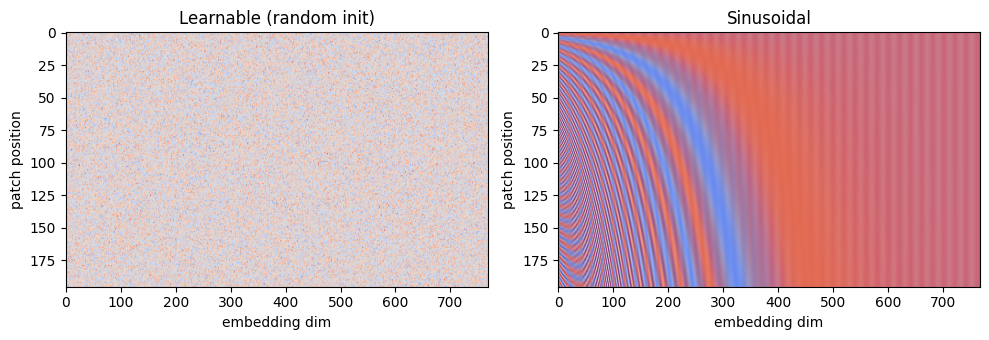

In [10]:
# (a) Learnable positional embeddings (as in the original ViT): one D-dim vector per position,
#     initialised randomly (small normal) and trained with the model.
pos_embeddings = rng.normal(0.0, 0.02, size=(num_patches, D)).astype(np.float32)
print("Positional embeddings shape:", pos_embeddings.shape, "(N, D)")

# (b) For comparison: fixed sinusoidal embeddings as in "Attention Is All You Need"
def sinusoidal(n_pos, dim):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(dim // 2)[None, :]
    angle = pos / (10000 ** (2 * i / dim))
    pe = np.zeros((n_pos, dim), dtype=np.float32)
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

pos_sin = sinusoidal(num_patches, D)
print("Sinusoidal alternative     :", pos_sin.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
im0 = ax[0].imshow(pos_embeddings, aspect="auto", cmap="coolwarm"); ax[0].set_title("Learnable (random init)")
im1 = ax[1].imshow(pos_sin, aspect="auto", cmap="coolwarm"); ax[1].set_title("Sinusoidal")
for a in ax: a.set_xlabel("embedding dim"); a.set_ylabel("patch position")
plt.tight_layout(); plt.show()

After creating the patch embeddings, we also need to add information about the position of each patch. The Transformer itself does not know where a patch came from just from its embedding, so positional information is added to the patch embeddings.

Since there are 196 patches and the embedding dimension is $D=768$, I create one positional embedding for each patch:

$$
E_{pos}\in\mathbb{R}^{196\times768}.
$$

The learnable positional embeddings therefore have shape $(196,768)$, which is the same as the shape of the patch embeddings.

In this exercise, the positional embeddings are randomly initialized. In a trained ViT, these values would be learned during training. I also included sinusoidal positional embeddings for comparison, but the main version used here is the learnable one.


### Step 9 — Add positional embeddings to patch embeddings

In [11]:
tokens = patch_embeddings + pos_embeddings
print("Patch embeddings   :", patch_embeddings.shape)
print("Positional embeds  :", pos_embeddings.shape)
print("Transformer input  :", tokens.shape, "(N, D)")

# Optional: standard ViT also prepends a learnable [CLS] token -> sequence length N+1
cls_token = rng.normal(0.0, 0.02, size=(1, D)).astype(np.float32)
pos_with_cls = rng.normal(0.0, 0.02, size=(num_patches + 1, D)).astype(np.float32)
tokens_cls = np.concatenate([cls_token, patch_embeddings], axis=0) + pos_with_cls
print("With [CLS] token   :", tokens_cls.shape, "(N+1, D)  <- what ViT-B/16 actually feeds to its encoder")

Patch embeddings   : (196, 768)
Positional embeds  : (196, 768)
Transformer input  : (196, 768) (N, D)
With [CLS] token   : (197, 768) (N+1, D)  <- what ViT-B/16 actually feeds to its encoder


The patch embeddings and positional embeddings both have shape $(196,768)$, so they can be added element-wise:

$$
\text{tokens}=\text{patch embeddings}+\text{positional embeddings}.
$$

The resulting shape is still

$$
(196,768).
$$

This means that we now have **196 tokens**, and each token has a 768-dimensional representation. The positional information is added to each patch embedding so that the Transformer can distinguish between patches from different positions.

For comparison, a standard ViT also uses a learnable `[CLS]` token. If it is added, the sequence contains 197 tokens instead of 196, giving a shape of $(197,768)$. I included this as an optional example, but the main result of this implementation is $(196,768)$.

### Summary of all shapes

In [12]:
summary = [
    ("Resized image",                         img_np.shape),
    ("Patches (N, P, P, C)",                  patches.shape),
    ("One patch (P, P, C)",                   one.shape),
    ("One flattened patch (P*P*C,)",          flat_one.shape),
    ("All flattened patches (N, P*P*C)",      patches_flat.shape),
    ("Projection matrix (P*P*C, D)",          W_proj.shape),
    ("Patch embeddings (N, D)",               patch_embeddings.shape),
    ("Positional embeddings (N, D)",          pos_embeddings.shape),
    ("Patch + positional (N, D)",             tokens.shape),
    ("With [CLS] token (N+1, D)",             tokens_cls.shape),
]

for name, shp in summary:
    print(f"{name:<38}{str(shp)}")

Resized image                         (224, 224, 3)
Patches (N, P, P, C)                  (196, 16, 16, 3)
One patch (P, P, C)                   (16, 16, 3)
One flattened patch (P*P*C,)          (768,)
All flattened patches (N, P*P*C)      (196, 768)
Projection matrix (P*P*C, D)          (768, 768)
Patch embeddings (N, D)               (196, 768)
Positional embeddings (N, D)          (196, 768)
Patch + positional (N, D)             (196, 768)
With [CLS] token (N+1, D)             (197, 768)


### Final result

The original $224\times224$ RGB image was divided into **196 patches** of size $16\times16$. Each patch contains $16\times16\times3=768$ values, which are flattened and projected into a 768-dimensional embedding. Positional embeddings of the same size are then added to these patch embeddings.

Therefore, the final input to the Transformer encoder in this implementation has shape

$$
\boxed{(196,768)}.
$$

This represents a sequence of 196 image patches, where each patch is represented by a 768-dimensional vector.


---
# 3. Pre-Trained Transformers

In [13]:
# !pip install -q transformers torch pillow scikit-image
from transformers import pipeline
import torch
device = 0 if torch.cuda.is_available() else -1
print("Device:", "GPU" if device == 0 else "CPU")

Device: CPU


## 3.1 NLP Transformer — Named Entity Recognition (NER)

**Task:** Named Entity Recognition (NER) identifies important entities in a text and assigns them labels such as `PER` (person), `ORG` (organization), and `LOC` (location).

**Model:** `dslim/bert-base-NER` — a pretrained BERT model fine-tuned for NER on the CoNLL-2003 dataset.

I use the HuggingFace `pipeline` with the `ner` task. The `aggregation_strategy="simple"` option combines consecutive word pieces when they belong to the same entity.


In [14]:
ner = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple", device=device)

texts = [
    "Albert Einstein was born in Ulm, Germany, and later worked at Princeton University in the United States.",
    "Anthropic, founded in San Francisco, released the Claude models, while Google and OpenAI compete in the same market.",
    "Vanadzor is a city in Armenia, and Yerevan State University is located in the capital.",
]
for t in texts:
    print("\nTEXT:", t)
    for e in ner(t):
        print(f"  {e['word']:<28} {e['entity_group']:<5} score={e['score']:.3f}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Some weights of the model checkpoint at dslim/bert-base-NER were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenCla


TEXT: Albert Einstein was born in Ulm, Germany, and later worked at Princeton University in the United States.
  Albert Einstein              PER   score=0.998
  Ulm                          LOC   score=0.966
  Germany                      LOC   score=1.000
  Princeton University         ORG   score=0.998
  United States                LOC   score=0.999

TEXT: Anthropic, founded in San Francisco, released the Claude models, while Google and OpenAI compete in the same market.
  An                           ORG   score=0.966
  ##ic                         ORG   score=0.914
  San Francisco                LOC   score=0.999
  Claude                       MISC  score=0.937
  Google                       ORG   score=0.999
  OpenAI                       ORG   score=0.996

TEXT: Vanadzor is a city in Armenia, and Yerevan State University is located in the capital.
  Vanadzor                     LOC   score=0.979
  Armenia                      LOC   score=1.000
  Yerevan State University     OR

### Comment on the NER Results

The model correctly identified most of the entities in the example sentences. For example, **Albert Einstein** was classified as `PER`, while **Germany**, **Ulm**, and **United States** were classified as `LOC`. **Princeton University**, **Google**, **OpenAI**, and **Yerevan State University** were correctly identified as organizations.

The model also recognized **Vanadzor** as a location with a high confidence score, even though it is a less common entity in the English news data used for training.

One mistake can be seen with **Anthropic**. Instead of returning the whole word as one entity, the tokenizer split it into `An` and `##ic`, and both parts were classified as `ORG`. This shows that pretrained NER models can still have difficulties with newer or less familiar organization names.

Overall, the model performed well on the examples, especially for common people, locations, and organizations. The confidence scores were also high for most of the correctly recognized entities.


## 3.2 Computer Vision Transformer — Image Classification

**Task:** classify an image into one of the ImageNet classes.

**Model:** `google/vit-base-patch16-224` — a pretrained Vision Transformer (ViT) with a $16\times16$ patch size and a $224\times224$ input size. It was pretrained on ImageNet-21k and fine-tuned on ImageNet-1k.

I use the HuggingFace `image-classification` pipeline to apply the pretrained model to the same cat image used in Part 2.


Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Device set to use cpu


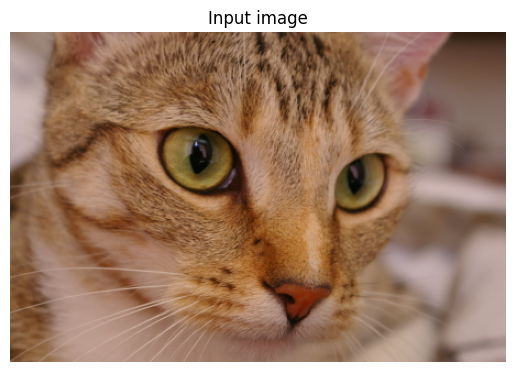

Egyptian cat                        0.9772
tiger cat                           0.0090
tabby, tabby cat                    0.0078
lynx, catamount                     0.0022
quilt, comforter, comfort, puff     0.0006


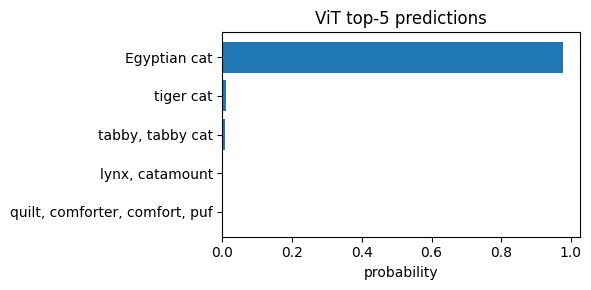

In [15]:
from PIL import Image
from skimage import data
import matplotlib.pyplot as plt

image = Image.fromarray(data.chelsea()).convert("RGB")   # same cat image as in Part 2
clf = pipeline("image-classification", model="google/vit-base-patch16-224", device=device)
preds = clf(image, top_k=5)

plt.imshow(image); plt.axis("off"); plt.title("Input image"); plt.show()
for p in preds:
    print(f"{p['label']:<35} {p['score']:.4f}")

plt.figure(figsize=(6, 3))
plt.barh([p["label"][:30] for p in preds][::-1], [p["score"] for p in preds][::-1])
plt.xlabel("probability"); plt.title("ViT top-5 predictions"); plt.tight_layout(); plt.show()

### Comment on the Image-Classification Results

The model correctly recognized the image as a cat. The top prediction was **Egyptian cat** with a probability of **0.9771**, which is much higher than the other predictions. The next predictions were **tiger cat** with 0.0090 and **tabby cat** with 0.0078.

The different cat labels show that ImageNet contains several fine-grained classes for similar types of cats. Even though the model chose `Egyptian cat` as the top class, the other high-ranked predictions also belong to the same general category.

This result also connects to Part 2. There, I manually divided the image into $16\times16$ patches and converted them into Transformer tokens. Here, the pretrained ViT performs the complete process automatically and uses the resulting representation to predict the image class.


## 3.3 Multimodal Transformer — Visual Question Answering (VQA)

**Task:** given an image and a natural-language question, produce a short answer.  
**Model:** `dandelin/vilt-b32-finetuned-vqa` — ViLT, a single Transformer that takes *both* text tokens and image patch embeddings (patch size 32) in one sequence, fine-tuned on VQAv2. As a second quick check the captioning model `Salesforce/blip-image-captioning-base` (image-to-text) is also run.

In [16]:
!pip install -q "transformers<5"

pytorch_model.bin:   0%|          | 0.00/470M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/320 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/470M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cpu


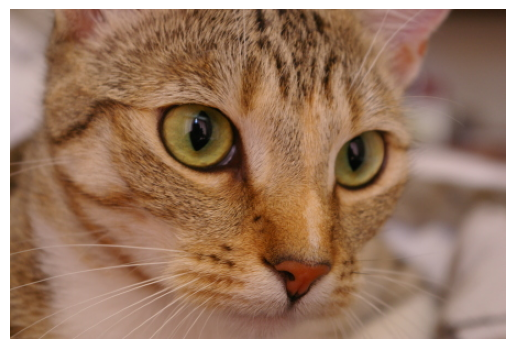

Q: What animal is in the picture?
    cat             0.997
    yes             0.026
    no              0.009
Q: What color is the animal?
    orange          0.456
    brown           0.294
    orange and white 0.250
Q: How many animals are there?
    1               0.997
    cat             0.007
    2               0.005
Q: Is the animal indoors or outdoors?
    indoors         0.976
    outdoors        0.125
    indoor          0.111
Q: What is the animal doing?
    staring         0.494
    looking         0.489
    sitting         0.369


In [17]:
vqa = pipeline("visual-question-answering", model="dandelin/vilt-b32-finetuned-vqa", device=device)

questions = [
    "What animal is in the picture?",
    "What color is the animal?",
    "How many animals are there?",
    "Is the animal indoors or outdoors?",
    "What is the animal doing?",
]
plt.imshow(image); plt.axis("off"); plt.show()
for q in questions:
    out = vqa(image=image, question=q, top_k=3)
    print(f"Q: {q}")
    for o in out:
        print(f"    {o['answer']:<15} {o['score']:.3f}")

In [18]:
# image-to-text (captioning) with a generative multimodal model
captioner = pipeline("image-to-text", model="Salesforce/blip-image-captioning-base", device=device)
print(captioner(image))

/usr/local/lib/python3.13/dist-packages/transformers/models/auto/modeling_auto.py:2284: FutureWarning: The class `AutoModelForVision2Seq` is deprecated and will be removed in v5.0. Please use `AutoModelForImageTextToText` instead.
  warnings.warn(


pytorch_model.bin:   0%|          | 0.00/990M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

Device set to use cpu


[{'generated_text': 'a cat with green eyes'}]


### Comment on the Multimodal Results

The ViLT model correctly answered the basic questions about the image. It identified the animal as a **cat** with a score of 0.997 and correctly identified that there is **one animal**, also with a score of 0.997. It also classified the image as **indoors** with a high score of 0.976.

The color question was less certain. The top answer was **orange** with a score of 0.456, followed by **brown** and **orange and white**. This shows that some visual properties can be more ambiguous than simply identifying the main object.

The question about what the animal is doing also had lower and more similar scores. The top answers were **staring** (0.494), **looking** (0.489), and **sitting** (0.369). This is reasonable because the image does not show a very specific action.

As a bonus, I also used the BLIP image-captioning model. It generated the caption **"a cat with green eyes"**, which correctly describes the main object and one of its visual features.

Overall, these results demonstrate how a multimodal Transformer can combine information from an image and natural language. ViLT uses the image together with the question to produce an answer, while BLIP uses the image to generate a natural-language description.
